# Load HCP parcellated task data
## (version with Behavioural Data)

The HCP dataset comprises task-based fMRI from a large sample of human subjects. The NMA-curated dataset includes time series data that has been preprocessed and spatially-downsampled by aggregating within 360 regions of interest.

In order to use this dataset, please electronically sign the HCP data use terms at [ConnectomeDB](https://db.humanconnectome.org). Instructions for this are on pp. 24-25 of the [HCP Reference Manual](https://www.humanconnectome.org/storage/app/media/documentation/s1200/HCP_S1200_Release_Reference_Manual.pdf).

In this notebook, NMA provides code for downloading the data and doing some basic visualisation and processing.

In [1]:
# @title Install dependencies
!pip install nilearn --quiet

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
# The data shared for NMA projects is a subset of the full HCP dataset
N_SUBJECTS = 100

# The data have already been aggregated into ROIs from the Glasser parcellation
N_PARCELS = 360

# The acquisition parameters for all tasks were identical
TR = 0.72  # Time resolution, in seconds

# The parcels are matched across hemispheres with the same order
HEMIS = ["Right", "Left"]

# Each experiment was repeated twice in each subject
RUNS   = ['LR','RL']
N_RUNS = 2

# There are 7 tasks. Each has a number of 'conditions'
# TIP: look inside the data folders for more fine-graned conditions
LOADS = ["0bk", "2bk"]
CATEGORIES = ["body", "faces", "places", "tools"]
CONDITIONS = [f"{load}_{cat}" for load in LOADS for cat in CATEGORIES]
EV_NAMES = ["all_bk_cor", "all_bk_err"]

EXPERIMENTS = {
    'MOTOR'      : {'cond':['lf','rf','lh','rh','t','cue']},
    'WM'         : {'cond':['0bk_body','0bk_faces','0bk_places','0bk_tools','2bk_body','2bk_faces','2bk_places','2bk_tools']},
    'EMOTION'    : {'cond':['fear','neut']},
    'GAMBLING'   : {'cond':['loss','win']},
    'LANGUAGE'   : {'cond':['math','story']},
    'RELATIONAL' : {'cond':['match','relation']},
    'SOCIAL'     : {'cond':['ment','rnd']}
}

In [4]:
# @title Download data file
import os, requests

fname = "hcp_task.tgz"
url = "https://osf.io/2y3fw/download"

if not os.path.isfile(fname):
  try:
    r = requests.get(url)
  except requests.ConnectionError:
    print("!!! Failed to download data !!!")
  else:
    if r.status_code != requests.codes.ok:
      print("!!! Failed to download data !!!")
    else:
      with open(fname, "wb") as fid:
        fid.write(r.content)

In [5]:
# The download cells will store the data in nested directories starting here:
HCP_DIR = "./hcp_task"

# importing the "tarfile" module
import tarfile

# open file
with tarfile.open(fname) as tfile:
  # extracting file
  tfile.extractall('.')


/tmp/ipykernel_3964/4265247334.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tfile.extractall('.')


###Loading information

In [6]:
subjects = np.loadtxt(os.path.join(HCP_DIR, 'subjects_list.txt'), dtype='str')

region_raw = np.load(f"{HCP_DIR}/regions.npy")
if region_raw.ndim != 2:
    raise ValueError(f"Unexpected regions.npy shape: {region_raw.shape}")

# The NMA dataset normally stores one row per parcel and columns [name, network].
if region_raw.shape[0] == N_PARCELS and region_raw.shape[1] >= 2:
    region_names = region_raw[:, 0].astype(str)
    region_networks = region_raw[:, 1].astype(str)
elif region_raw.shape[1] == N_PARCELS and region_raw.shape[0] >= 2:
    region_raw = region_raw.T
    region_names = region_raw[:, 0].astype(str)
    region_networks = region_raw[:, 1].astype(str)
else:
    raise ValueError(f"Cannot interpret regions.npy shape {region_raw.shape} as {N_PARCELS} parcels")


In [7]:
hemispheres = np.array(["Right"] * (N_PARCELS // 2) + ["Left"] * (N_PARCELS // 2))
region_table = pd.DataFrame({
    "parcel_index": np.arange(N_PARCELS),
    "parcel_name": region_names,
    "network": region_networks,
    "hemisphere": hemispheres,
})

print(f"Subjects listed: {len(subjects)}")
print(f"Parcel labels loaded: {len(region_table)}")
display(region_table.head())

Subjects listed: 100
Parcel labels loaded: 360


,parcel_index,parcel_name,network,hemisphere
0,0,R_V1,Visual1,Right
1,1,R_MST,Visual2,Right
2,2,R_V6,Visual2,Right
3,3,R_V2,Visual2,Right
4,4,R_V3,Visual2,Right


###Read events and ROI time series

In [30]:
from pathlib import Path

def run_folder_for(subject_id, run_code):
    return (
        Path(HCP_DIR) / "subjects" / str(subject_id) / "WM"
        / f"tfMRI_WM_{run_code}"
    )


def read_run_events(subject_id, run_code):
    """Read eight condition EVs and optional correct/error EVs for one run."""
    ev_dir = run_folder_for(subject_id, run_code) / "EVs"
    if not ev_dir.is_dir():
        raise FileNotFoundError(f"Missing EV directory: {ev_dir}")

    records = []
    ev_names = CONDITIONS + EV_NAMES

    for ev_name in ev_names:
        ev_path = ev_dir / f"{ev_name}.txt"
        if not ev_path.exists():
            if ev_name in CONDITIONS:
                raise FileNotFoundError(f"Missing condition EV: {ev_path}")
            # Correct/error EVs are optional in some versions of the data.
            continue
        if ev_path.stat().st_size == 0:
            continue

        values = np.loadtxt(ev_path, ndmin=2)
        if values.size == 0:
            continue
        if values.shape[1] < 2:
            raise ValueError(f"Expected onset and duration columns in {ev_path}; got {values.shape}")

        for row in values:
            onset = float(row[0])
            duration = float(row[1])
            modulation = float(row[2]) if values.shape[1] >= 3 else 1.0
            if duration < 0:
                raise ValueError(f"Negative duration in {ev_path}: {duration}")
            records.append({
                "onset": onset,
                "duration": duration,
                "trial_type": ev_name,
                "modulation": modulation,
            })

    events = pd.DataFrame(records, columns=["onset", "duration", "trial_type", "modulation"])
    if events.empty:
        raise ValueError(f"No events read for subject {subject_id}, run {run_code}")

    found_conditions = set(events["trial_type"]) & set(CONDITIONS)
    missing_conditions = sorted(set(CONDITIONS) - found_conditions)
    if missing_conditions:
        raise ValueError(
            f"Missing event rows for {missing_conditions} in subject {subject_id}, run {run_code}. "
            "Check whether these EV files are empty or named differently."
        )
    return events


def load_run_timeseries(subject_id, run_code):
    """Return ROI time series as (time points, 360 parcels)."""
    data_path = run_folder_for(subject_id, run_code) / "data.npy"
    if not data_path.is_file():
        raise FileNotFoundError(f"Missing time-series file: {data_path}")

    data = np.load(data_path).astype(np.float64)
    if data.ndim != 2:
        raise ValueError(f"Expected a 2D time series in {data_path}; got {data.shape}")
    if data.shape[0] == N_PARCELS:
        data = data.T
    elif data.shape[1] == N_PARCELS:
        pass
    else:
        raise ValueError(f"Expected one dimension to equal {N_PARCELS} in {data_path}; got {data.shape}")
    if not np.isfinite(data).all():
        raise ValueError(f"Non-finite values found in {data_path}")
    return data

###First-level ROI GLM

In [9]:
import warnings
from nilearn.glm.first_level import make_first_level_design_matrix

def fit_run_roi_glm(subject_id, run_code):
    """Fit a simple HRF-convolved OLS model; return condition beta vectors and diagnostics."""
    Y = load_run_timeseries(subject_id, run_code)  # time x parcels
    events = read_run_events(subject_id, run_code)
    frame_times = np.arange(Y.shape[0], dtype=float) * TR

    design = make_first_level_design_matrix(
        frame_times=frame_times,
        events=events,
        hrf_model="glover",
        drift_model="cosine",
        high_pass=0.01,
    )

    missing = [condition for condition in CONDITIONS if condition not in design.columns]
    if missing:
        raise ValueError(
            f"Design matrix is missing regressors {missing} for subject {subject_id}, run {run_code}. "
            f"Design columns: {design.columns.tolist()}"
        )

    X = design.to_numpy(dtype=float)
    if not np.isfinite(X).all():
        raise ValueError(f"Non-finite design matrix for {subject_id}, run {run_code}")

    beta_hat, _, rank, _ = np.linalg.lstsq(X, Y, rcond=None)
    if rank < X.shape[1]:
        warnings.warn(
            f"Rank-deficient design for {subject_id}, {run_code}: rank {rank} < {X.shape[1]} columns. "
            "Inspect overlapping/empty EVs before interpreting the beta estimates."
        )

    beta_by_condition = {
        condition: beta_hat[design.columns.get_loc(condition), :].copy()
        for condition in CONDITIONS
    }
    diagnostics = {
        "subject": str(subject_id),
        "run": run_code,
        "n_timepoints": Y.shape[0],
        "n_regressors": X.shape[1],
        "design_rank": int(rank),
    }
    return beta_by_condition, design, diagnostics


# Smoke-test one run before launching all subjects.
test_subject = subjects[0]
test_beta, test_design, test_diag = fit_run_roi_glm(test_subject, RUNS[0])
print("Test run:", test_diag)
print("Condition regressors present:", all(c in test_design.columns for c in CONDITIONS))
display(test_design.head())

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

Test run: {'subject': '100307', 'run': 'LR', 'n_timepoints': 405, 'n_regressors': 16, 'design_rank': 16}
Condition regressors present: True


,0bk_body,0bk_faces,0bk_places,0bk_tools,2bk_body,2bk_faces,2bk_places,2bk_tools,all_bk_cor,all_bk_err,drift_1,drift_2,drift_3,drift_4,drift_5,constant
0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.070272,0.070271,0.070268,0.070264,0.070260,1.0
0.72,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.070268,0.070254,0.070230,0.070197,0.070154,1.0
1.44,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.070260,0.070220,0.070154,0.070062,0.069943,1.0
2.16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.070247,0.070169,0.070040,0.069859,0.069626,1.0
2.88,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.070230,0.070102,0.069888,0.069589,0.069205,1.0


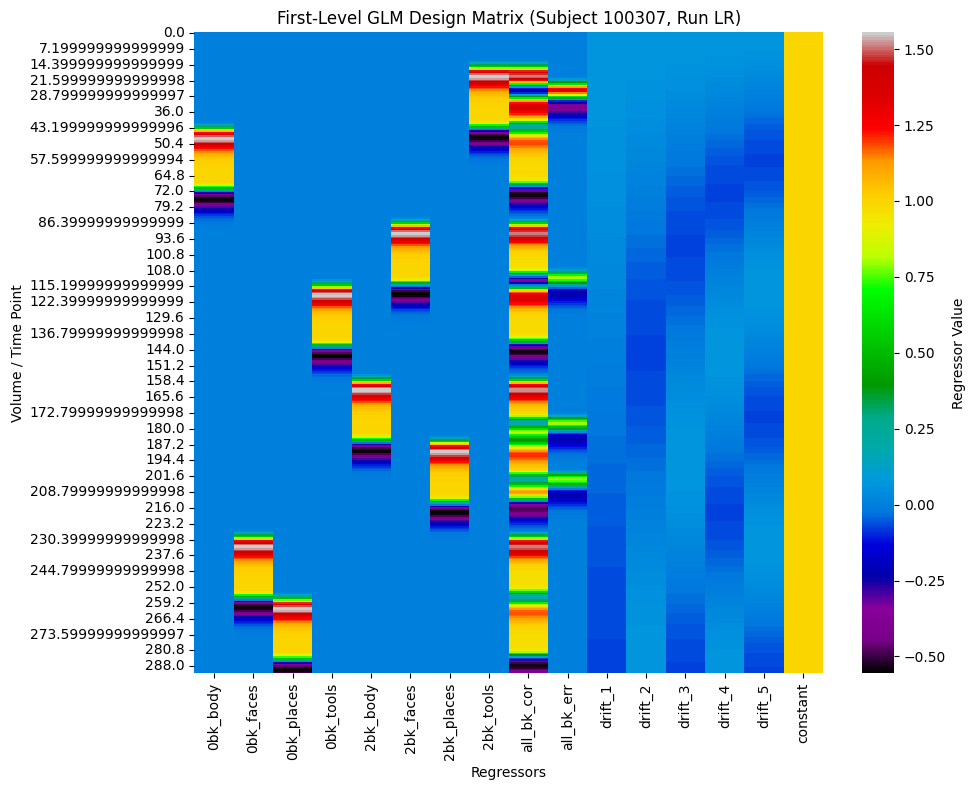

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(test_design, cmap='nipy_spectral', cbar_kws={'label': 'Regressor Value'})
plt.title('First-Level GLM Design Matrix (Subject 100307, Run LR)')
plt.xlabel('Regressors')
plt.ylabel('Volume / Time Point')
plt.tight_layout()
plt.show()

What the visualization shows:
Task Conditions (0bk_body to 2bk_tools): You can clearly see the distinct block periods during which specific stimuli were presented (visible as the bright white convolved hemodynamic response function blocks). Because the task blocks do not overlap in time, these regressors are mutually exclusive (except for minor overlap at block transitions due to hemodynamic lag).
Performance Covariates (all_bk_cor, all_bk_err): These capture task-related responses based on behavioral performance.
Drift Regressors (drift_1 to drift_5): These are low-frequency cosine waves designed to model and remove scanner drift and slow physiological noise.
Constant: A flat regressor modeling baseline signal intensity.

In [11]:
run_betas = np.full(
    (len(subjects), len(RUNS), len(CONDITIONS), N_PARCELS),
    np.nan,
    dtype=float,
)
design_diagnostics = []

for si, subject_id in enumerate(subjects):
    for ri, run_code in enumerate(RUNS):
        beta_by_condition, _, diag = fit_run_roi_glm(subject_id, run_code)
        design_diagnostics.append(diag)
        for ci, condition in enumerate(CONDITIONS):
            run_betas[si, ri, ci, :] = beta_by_condition[condition]
    if (si + 1) % 10 == 0 or si == len(subjects) - 1:
        print(f"Processed {si + 1}/{len(subjects)} subjects")

if not np.isfinite(run_betas).all():
    bad = np.argwhere(~np.isfinite(run_betas))[0].tolist()
    raise ValueError(f"Missing/non-finite beta value; first array index is {bad}")

# Combine runs within each participant: shape (subjects, conditions, parcels).
condition_betas = run_betas.mean(axis=1)
condition_index = {condition: i for i, condition in enumerate(CONDITIONS)}

design_diagnostics = pd.DataFrame(design_diagnostics)
print("run_betas shape:", run_betas.shape)
print("condition_betas shape:", condition_betas.shape)
display(design_diagnostics.head())

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

...

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

[make_first_level_design_matrix] A 'modulation' column was found in the given events data and is used.

Processed 100/100 subjects
run_betas shape: (100, 2, 8, 360)
condition_betas shape: (100, 8, 360)


,subject,run,n_timepoints,n_regressors,design_rank
0,100307,LR,405,16,16
1,100307,RL,405,16,16
2,100408,LR,405,16,16
3,100408,RL,405,16,16
4,101915,LR,405,16,16


###Build tidy data for group-level tests

In [12]:
beta_long = pd.DataFrame({
    "subject": np.repeat(np.asarray(subjects, dtype=str), len(CONDITIONS) * N_PARCELS),
    "condition": np.tile(np.repeat(np.asarray(CONDITIONS, dtype=str), N_PARCELS), len(subjects)),
    "parcel_index": np.tile(np.arange(N_PARCELS), len(subjects) * len(CONDITIONS)),
    "beta": condition_betas.reshape(-1),
})
beta_long["load"] = beta_long["condition"].str.split("_").str[0]
beta_long["category"] = beta_long["condition"].str.split("_").str[1]
beta_long = beta_long.merge(region_table, on="parcel_index", how="left", validate="many_to_one")

expected_rows = len(subjects) * len(CONDITIONS) * N_PARCELS
if len(beta_long) != expected_rows:
    raise RuntimeError(f"Unexpected long-table row count: {len(beta_long)} != {expected_rows}")
print("Rows in group-analysis table:", len(beta_long))
display(beta_long.head())

Rows in group-analysis table: 288000


,subject,condition,parcel_index,beta,load,category,parcel_name,network,hemisphere
0,100307,0bk_body,0,35.872272,0bk,body,R_V1,Visual1,Right
1,100307,0bk_body,1,10.580654,0bk,body,R_MST,Visual2,Right
2,100307,0bk_body,2,12.822464,0bk,body,R_V6,Visual2,Right
3,100307,0bk_body,3,20.901997,0bk,body,R_V2,Visual2,Right
4,100307,0bk_body,4,18.604157,0bk,body,R_V3,Visual2,Right


###Two-way repeated-measures ANOVA at each parcel

In [13]:
!pip install pingouin --quiet
import pingouin as pg
from statsmodels.stats.multitest import multipletests

effect_name_map = {
    "load": "load",
    "category": "category",
    "load*category": "load_by_category",
    "category*load": "load_by_category",
}
anova_rows = []

for parcel_idx, parcel_data in beta_long.groupby("parcel_index", sort=True):
    aov = pg.rm_anova(
        data=parcel_data,
        dv="beta",
        within=["load", "category"],
        subject="subject",
        correction=True,
        detailed=True,
        effsize="ng2",
    )

    for _, row in aov.iterrows():
        source_key = str(row["Source"]).lower().replace(" ", "")
        if source_key not in effect_name_map:
            continue
        p_unc = float(row["p_unc"])
        p_gg = row.get("p_GG_corr", np.nan)
        p_gg = float(p_gg) if pd.notna(p_gg) else p_unc
        anova_rows.append({
            "parcel_index": int(parcel_idx),
            "parcel_name": region_names[int(parcel_idx)],
            "network": region_networks[int(parcel_idx)],
            "effect": effect_name_map[source_key],
            "df1": float(row["ddof1"]),
            "df2": float(row["ddof2"]),
            "F": float(row["F"]),
            "p_unc": p_unc,
            "p_GG_corr": p_gg,
            "generalized_eta_squared": float(row["ng2"]) if pd.notna(row.get("ng2", np.nan)) else np.nan,
            "epsilon_GG": float(row["eps"]) if pd.notna(row.get("eps", np.nan)) else np.nan,
        })

anova_results = pd.DataFrame(anova_rows)
anova_results["p_fdr"] = np.nan
anova_results["significant_fdr"] = False

for effect in ["load", "category", "load_by_category"]:
    mask = anova_results["effect"].eq(effect) & anova_results["p_GG_corr"].notna()
    if mask.any():
        p_adj = multipletests(anova_results.loc[mask, "p_GG_corr"].to_numpy(), method="fdr_bh")[1]
        anova_results.loc[mask, "p_fdr"] = p_adj
        anova_results.loc[mask, "significant_fdr"] = p_adj < 0.05

print("Significant parcels by effect after FDR:")
print(anova_results.groupby("effect")["significant_fdr"].sum())
display(anova_results[anova_results["significant_fdr"]].sort_values("p_fdr").head(20))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
Significant parcels by effect after FDR:
effect
category            284
load                272
load_by_category    171
Name: significant_fdr, dtype: int64


,parcel_index,parcel_name,network,effect,df1,df2,F,p_unc,p_GG_corr,generalized_eta_squared,epsilon_GG,p_fdr,significant_fdr
460,153,R_VMV3,Visual2,category,3.0,297.0,280.640154,2.451187e-86,8.732298e-78,0.305901,0.897505,3.143627e-75,True
1012,337,L_V3CD,Visual2,category,3.0,297.0,254.640832,9.098469e-82,1.406874e-74,0.288336,0.908854,2.532373e-72,True
379,126,R_PHA3,Language,category,3.0,297.0,235.701733,3.191485e-78,6.476743e-72,0.287133,0.916282,7.772091e-70,True
472,157,R_V3CD,Visual2,category,3.0,297.0,247.129840,2.196165e-80,1.709433e-69,0.354733,0.859473,1.538489e-67,True
478,159,R_VMV2,Visual2,category,3.0,297.0,286.134886,2.908774e-87,2.253437e-65,0.325517,0.740577,1.622475e-63,True
1000,333,L_VMV3,Visual2,category,3.0,297.0,220.783733,2.755963e-75,1.789140e-63,0.267910,0.836892,1.073484e-61,True
919,306,L_PHA3,Language,category,3.0,297.0,195.580507,5.324003e-70,3.513476e-61,0.224080,0.868656,1.806930e-59,True
463,154,R_PHA2,Posterior-Mu,category,3.0,297.0,187.238351,3.764930e-68,5.127685e-60,0.248206,0.875442,2.307458e-58,True
16,5,R_V4,Visual2,category,3.0,297.0,146.442105,2.969201e-58,5.453482e-56,0.161720,0.959162,2.181393e-54,True
427,142,R_PGp,Language,category,3.0,297.0,163.791374,1.194552e-62,1.805977e-55,0.194182,0.879988,6.501518e-54,True


Group-Level RM-ANOVA Results Explained

The repeated-measures ANOVA has executed successfully across all 360 brain parcels for the effects of cognitive load (0-bk vs. 2-bk), stimulus category (body, faces, places, tools), and their interaction (load $\times$$\times$ category).

After applying False Discovery Rate (FDR) correction (using the Benjamini-Hochberg method, $q < 0.05$$q < 0.05$), we find highly widespread significant effects across the brain:

Main Effect of Stimulus Category (284 / 360 significant parcels):

An overwhelming majority of brain regions show activity that is strongly modulated by the type of visual stimulus presented.
The top most significant parcels are localized in the visual streams and high-level category areas, such as R_VMV3 (Ventromedial Visual Area 3), L_V3CD, and R_PHA3 (Parahippocampal Area 3), with astronomical statistical significance (e.g., $F_{3, 297} \approx 280.64, p_{\text{FDR}} \approx 3.14 \times 10^{-75}$$F_{3, 297} \approx 280.64, p_{\text{FDR}} \approx 3.14 \times 10^{-75}$).
Main Effect of Cognitive Load (272 / 360 significant parcels):

272 parcels show a significant change in activation when moving from the low-demand monitoring condition (0-bk) to the high-demand working memory condition (2-bk). This represents the broad engagement of the frontoparietal, dorsal attention, and default mode networks during active cognitive manipulation.
Load $\times$$\times$ Category Interaction (171 / 360 significant parcels):

171 parcels show a significant interaction, indicating that the difference in activation between categories depends heavily on the level of cognitive load. This is a crucial finding, showing that loading working memory alters how sensory or category-specific info is integrated or prioritized.

###Paired post-hoc category comparisons at each parcel

In [14]:
from itertools import combinations
from scipy.stats import ttest_rel

posthoc_rows = []

for load in LOADS:
    for cat_a, cat_b in combinations(CATEGORIES, 2):
        idx_a = condition_index[f"{load}_{cat_a}"]
        idx_b = condition_index[f"{load}_{cat_b}"]
        x = condition_betas[:, idx_a, :]  # subjects x parcels
        y = condition_betas[:, idx_b, :]
        diff = x - y
        t_values, p_values = ttest_rel(x, y, axis=0, nan_policy="omit")
        mean_diff = np.nanmean(diff, axis=0)
        sd_diff = np.nanstd(diff, axis=0, ddof=1)
        dz = np.divide(mean_diff, sd_diff, out=np.full_like(mean_diff, np.nan), where=sd_diff > 0)

        for parcel_idx in range(N_PARCELS):
            posthoc_rows.append({
                "load": load,
                "comparison": f"{cat_a} - {cat_b}",
                "category_a": cat_a,
                "category_b": cat_b,
                "parcel_index": parcel_idx,
                "parcel_name": region_names[parcel_idx],
                "network": region_networks[parcel_idx],
                "mean_difference_a_minus_b": mean_diff[parcel_idx],
                "cohens_dz": dz[parcel_idx],
                "t": t_values[parcel_idx],
                "p_unc": p_values[parcel_idx],
            })

posthoc_results = pd.DataFrame(posthoc_rows)
valid = posthoc_results["p_unc"].notna()
posthoc_results["p_fdr_all_pairs_parcels"] = np.nan
posthoc_results["significant_fdr"] = False
if valid.any():
    p_adj = multipletests(posthoc_results.loc[valid, "p_unc"].to_numpy(), method="fdr_bh")[1]
    posthoc_results.loc[valid, "p_fdr_all_pairs_parcels"] = p_adj
    posthoc_results.loc[valid, "significant_fdr"] = p_adj < 0.05

print("Significant parcel-level pairwise tests after global FDR:", int(posthoc_results["significant_fdr"].sum()))
display(posthoc_results[posthoc_results["significant_fdr"]].sort_values("p_fdr_all_pairs_parcels").head(20))

Significant parcel-level pairwise tests after global FDR: 1749


,load,comparison,category_a,category_b,parcel_index,parcel_name,network,mean_difference_a_minus_b,cohens_dz,t,p_unc,p_fdr_all_pairs_parcels,significant_fdr
1417,0bk,faces - places,faces,places,337,L_V3CD,Visual2,-65.421273,-2.399625,-23.996247,4.741136e-43,2.048171e-39,True
1237,0bk,faces - places,faces,places,157,R_V3CD,Visual2,-70.089259,-2.338367,-23.383668,4.193818e-42,9.058647e-39,True
1233,0bk,faces - places,faces,places,153,R_VMV3,Visual2,-76.249282,-2.201470,-22.014700,6.338947e-40,6.846063e-37,True
3366,2bk,faces - places,faces,places,126,R_PHA3,Language,-71.962666,-2.208294,-22.082940,4.911812e-40,6.846063e-37,True
1239,0bk,faces - places,faces,places,159,R_VMV2,Visual2,-89.518333,-2.031382,-20.313818,4.349349e-37,3.757838e-34,True
3573,2bk,faces - places,faces,places,333,L_VMV3,Visual2,-90.919479,-2.005339,-20.053391,1.218421e-36,8.772633e-34,True
3393,2bk,faces - places,faces,places,153,R_VMV3,Visual2,-84.735634,-1.930908,-19.309081,2.421590e-35,1.494467e-32,True
3399,2bk,faces - places,faces,places,159,R_VMV2,Visual2,-94.668172,-1.847053,-18.470534,7.626080e-34,4.118083e-31,True
3394,2bk,faces - places,faces,places,154,R_PHA2,Posterior-Mu,-69.691275,-1.812848,-18.128481,3.194414e-33,1.533319e-30,True
3397,2bk,faces - places,faces,places,157,R_V3CD,Visual2,-62.515718,-1.719708,-17.197076,1.701654e-31,6.682859e-29,True


###target-versus-average-of-other-categories selectivity

In [15]:
from scipy.stats import ttest_1samp
selectivity_rows = []

for load in LOADS:
    for target in CATEGORIES:
        target_idx = condition_index[f"{load}_{target}"]
        other_conditions = [f"{load}_{cat}" for cat in CATEGORIES if cat != target]
        other_indices = [condition_index[c] for c in other_conditions]

        target_values = condition_betas[:, target_idx, :]
        other_values = condition_betas[:, other_indices, :].mean(axis=1)
        diff = target_values - other_values
        t_values, p_values = ttest_1samp(diff, popmean=0, axis=0, nan_policy="omit")

        for parcel_idx in range(N_PARCELS):
            selectivity_rows.append({
                "load": load,
                "target_category": target,
                "contrast": f"{load}_{target} - mean(other categories)",
                "parcel_index": parcel_idx,
                "parcel_name": region_names[parcel_idx],
                "network": region_networks[parcel_idx],
                "mean_difference": np.nanmean(diff[:, parcel_idx]),
                "t": t_values[parcel_idx],
                "p_unc": p_values[parcel_idx],
            })

selectivity_results = pd.DataFrame(selectivity_rows)
valid = selectivity_results["p_unc"].notna()
selectivity_results["p_fdr_all_selectivity_tests"] = np.nan
selectivity_results["significant_fdr"] = False
if valid.any():
    p_adj = multipletests(selectivity_results.loc[valid, "p_unc"].to_numpy(), method="fdr_bh")[1]
    selectivity_results.loc[valid, "p_fdr_all_selectivity_tests"] = p_adj
    selectivity_results.loc[valid, "significant_fdr"] = p_adj < 0.05

print("Significant selectivity tests after FDR:", int(selectivity_results["significant_fdr"].sum()))
display(selectivity_results[selectivity_results["significant_fdr"]].sort_values("p_fdr_all_selectivity_tests").head(20))

Significant selectivity tests after FDR: 1160


,load,target_category,contrast,parcel_index,parcel_name,network,mean_difference,t,p_unc,p_fdr_all_selectivity_tests,significant_fdr
1057,0bk,places,0bk_places - mean(other categories),337,L_V3CD,Visual2,50.865331,20.131776,8.928364e-37,2.571369e-33,True
873,0bk,places,0bk_places - mean(other categories),153,R_VMV3,Visual2,61.907307,19.512751,1.061493e-35,1.528549e-32,True
2286,2bk,places,2bk_places - mean(other categories),126,R_PHA3,Language,52.179046,19.303724,2.474865e-35,2.375870e-32,True
877,0bk,places,0bk_places - mean(other categories),157,R_V3CD,Visual2,55.286274,18.817146,1.813075e-34,1.305414e-31,True
879,0bk,places,0bk_places - mean(other categories),159,R_VMV2,Visual2,74.658419,18.452868,8.208698e-34,4.728210e-31,True
2493,2bk,places,2bk_places - mean(other categories),333,L_VMV3,Visual2,57.099176,18.226343,2.117182e-33,1.016247e-30,True
725,0bk,places,0bk_places - mean(other categories),5,R_V4,Visual2,38.179468,18.148047,2.941948e-33,1.210401e-30,True
2314,2bk,places,2bk_places - mean(other categories),154,R_PHA2,Posterior-Mu,55.786086,18.005077,5.375238e-33,1.935086e-30,True
1953,2bk,faces,2bk_faces - mean(other categories),153,R_VMV3,Visual2,-56.959926,-17.820308,1.175840e-32,3.762690e-30,True
1926,2bk,faces,2bk_faces - mean(other categories),126,R_PHA3,Language,-43.771176,-17.784213,1.370814e-32,3.947946e-30,True


###selectivity between 0-back and 2-back

In [16]:
from statsmodels.stats.multitest import multipletests

selectivity_load_rows = []

for target in CATEGORIES:
    idx_0 = condition_index[f"0bk_{target}"]
    idx_2 = condition_index[f"2bk_{target}"]

    others_0 = [
        condition_index[f"0bk_{cat}"]
        for cat in CATEGORIES if cat != target
    ]
    others_2 = [
        condition_index[f"2bk_{cat}"]
        for cat in CATEGORIES if cat != target
    ]

    # Shape: participants x parcels
    selectivity_0 = (
        condition_betas[:, idx_0, :]
        - condition_betas[:, others_0, :].mean(axis=1)
    )

    selectivity_2 = (
        condition_betas[:, idx_2, :]
        - condition_betas[:, others_2, :].mean(axis=1)
    )

    # Positive values indicate increased selectivity at 2-back
    # relative to 0-back.
    delta_selectivity = selectivity_2 - selectivity_0

    t_values, p_values = ttest_1samp(
        delta_selectivity,
        popmean=0,
        axis=0,
        nan_policy="omit"
    )

    for parcel_idx in range(N_PARCELS):
        selectivity_load_rows.append({
            "target_category": target,
            "parcel_index": parcel_idx,
            "parcel_name": region_names[parcel_idx],
            "network": region_networks[parcel_idx],
            "mean_change_2bk_minus_0bk":
                np.nanmean(delta_selectivity[:, parcel_idx]),
            "t": t_values[parcel_idx],
            "p_unc": p_values[parcel_idx],
        })

selectivity_load_results = pd.DataFrame(selectivity_load_rows)

valid = selectivity_load_results["p_unc"].notna()
selectivity_load_results["p_fdr"] = np.nan
selectivity_load_results["significant_fdr"] = False

if valid.any():
    p_adj = multipletests(
        selectivity_load_results.loc[valid, "p_unc"].to_numpy(),
        method="fdr_bh"
    )[1]

    selectivity_load_results.loc[valid, "p_fdr"] = p_adj
    selectivity_load_results.loc[valid, "significant_fdr"] = p_adj < 0.05

print(
    "Significant load-related selectivity changes after FDR:",
    int(selectivity_load_results["significant_fdr"].sum())
)

display(
    selectivity_load_results[
        selectivity_load_results["significant_fdr"]
    ].sort_values("p_fdr").head(20)
)

Significant load-related selectivity changes after FDR: 278


,target_category,parcel_index,parcel_name,network,mean_change_2bk_minus_0bk,t,p_unc,p_fdr,significant_fdr
185,body,185,L_V4,Visual2,21.007567,6.471642,3.735693e-09,0.000004,True
693,faces,333,L_VMV3,Visual2,-29.045651,-6.399905,5.211239e-09,0.000004,True
543,faces,183,L_V2,Visual2,-17.538160,-6.203733,1.285756e-08,0.000005,True
1249,tools,169,R_p10p,Frontopariet,-26.390041,-6.203763,1.285580e-08,0.000005,True
91,body,91,R_13l,Frontopariet,33.021645,6.104846,2.018592e-08,0.000006,True
739,places,19,R_LO1,Visual2,-18.655536,-5.898246,5.129869e-08,0.000008,True
5,body,5,R_V4,Visual2,19.513056,5.905001,4.976872e-08,0.000008,True
540,faces,180,L_V1,Visual1,-21.395510,-5.934759,4.354596e-08,0.000008,True
1152,tools,72,R_8C,Frontopariet,-19.867725,-5.911587,4.832020e-08,0.000008,True
337,body,337,L_V3CD,Visual2,18.171235,5.874647,5.701618e-08,0.000008,True


###Summarize all 278 significant results

In [17]:
significant = selectivity_load_results[
    selectivity_load_results["significant_fdr"]
].copy()

print("Significant tests:", len(significant))
print("Unique parcels:", significant["parcel_index"].nunique())

print("\nSignificant tests by category:")
display(
    significant.groupby("target_category")
    .size()
    .sort_values(ascending=False)
    .rename("n_significant_tests")
    .to_frame()
)

print("\nSignificant tests by category and network:")
display(
    significant.groupby(["target_category", "network"])
    .size()
    .rename("n_significant_tests")
    .reset_index()
    .sort_values("n_significant_tests", ascending=False)
)

Significant tests: 278
Unique parcels: 189

Significant tests by category:


,n_significant_tests
target_category,
faces,129
tools,69
places,54
body,26



Significant tests by category and network:


,target_category,network,n_significant_tests
12,faces,Somatomotor,31
25,tools,Frontopariet,27
14,faces,Visual2,26
21,places,Visual2,21
6,faces,Cingulo-Oper,18
4,body,Visual2,18
8,faces,Frontopariet,17
19,places,Posterior-Mu,12
5,faces,Auditory,11
20,places,Somatomotor,10


examine the direction of significant findings

In [18]:
# Keep only FDR-significant load-related selectivity results
significant = selectivity_load_results.loc[
    selectivity_load_results["significant_fdr"]
].copy()

# Determine the direction of each significant change
significant["direction"] = np.where(
    significant["mean_change_2bk_minus_0bk"] > 0,
    "Increased at 2-back",
    "Decreased at 2-back"
)

print("Direction by target category:")
display(
    significant.groupby(
        ["target_category", "direction"]
    ).size().unstack(fill_value=0)
)

print("\nDirection by target category and network:")
display(
    significant.groupby(
        ["target_category", "network", "direction"]
    ).size().unstack(fill_value=0)
)

Direction by target category:


direction,Decreased at 2-back,Increased at 2-back
target_category,,
body,0,26
faces,92,37
places,24,30
tools,50,19



Direction by target category and network:


direction                     Decreased at 2-back  Increased at 2-back
target_category network                                               
body            Cingulo-Oper                    0                    1
                Frontopariet                    0                    3
                Language                        0                    2
                Visual1                         0                    2
                Visual2                         0                   18
faces           Auditory                       11                    0
                Cingulo-Oper                   17                    1
                Default                         2                    4
                Frontopariet                    1                   16
                Language                        1                    5
                Orbito-Affec                    1                    0
                Posterior-Mu                    8                    2
                Somatomotor                    31                    0
                Visual1                         3                    0
                Visual2                        17                    9
places          Cingulo-Oper                    0                    3
                Default                         0                    1
                Frontopariet                    0                    4
                Language                        3                    0
                Posterior-Mu                    0                   12
                Somatomotor                     0                   10
                Visual2                        21                    0
tools           Auditory                        0                    6
                Cingulo-Oper                    4                    4
                Default                         7                    0
                Frontopariet                   27                    0
                Language                        3                    0
                Posterior-Mu                    9                    0
                Somatomotor                     0                    3
                Visual2                         0                    6

In [19]:
# Number of parcels assigned to each network
network_sizes = (
    pd.Series(region_networks, name="network")
    .value_counts()
    .rename("total_parcels")
)

# Number of significant tests for each category and network
network_summary = (
    significant.groupby(["target_category", "network"])
    .size()
    .rename("significant_parcels")
    .reset_index()
)

network_summary["total_parcels"] = (
    network_summary["network"].map(network_sizes)
)

network_summary["percent_significant"] = (
    100 * network_summary["significant_parcels"]
    / network_summary["total_parcels"]
)

display(
    network_summary.sort_values(
        ["target_category", "percent_significant"],
        ascending=[True, False]
    )
)

,target_category,network,significant_parcels,total_parcels,percent_significant
3,body,Visual1,2,6,33.333333
4,body,Visual2,18,54,33.333333
2,body,Language,2,23,8.695652
1,body,Frontopariet,3,50,6.000000
0,body,Cingulo-Oper,1,56,1.785714
12,faces,Somatomotor,31,39,79.487179
5,faces,Auditory,11,15,73.333333
13,faces,Visual1,3,6,50.000000
14,faces,Visual2,26,54,48.148148
8,faces,Frontopariet,17,50,34.000000


Correct for unequal network sizes

In [20]:
results = selectivity_load_results.copy()

# Include every parcel with a valid statistical test
results = results.loc[results["p_unc"].notna()].copy()

# Direction among FDR-significant results
change = results["mean_change_2bk_minus_0bk"]
sig = results["significant_fdr"].astype(bool)

results["sig_increased"] = sig & (change > 0)
results["sig_decreased"] = sig & (change < 0)

network_summary = (
    results.groupby(["target_category", "network"])
    .agg(
        n_tested=("p_unc", "count"),
        n_significant=("significant_fdr", "sum"),
        n_sig_increased=("sig_increased", "sum"),
        n_sig_decreased=("sig_decreased", "sum"),
        mean_change_all_parcels=(
            "mean_change_2bk_minus_0bk", "mean"
        ),
        median_change_all_parcels=(
            "mean_change_2bk_minus_0bk", "median"
        ),
    )
    .reset_index()
)

network_summary["percent_significant"] = (
    100 * network_summary["n_significant"]
    / network_summary["n_tested"]
)

display(
    network_summary.sort_values(
        ["target_category", "percent_significant"],
        ascending=[True, False]
    ).round(2)
)

,target_category,network,n_tested,n_significant,n_sig_increased,n_sig_decreased,mean_change_all_parcels,median_change_all_parcels,percent_significant
10,body,Visual1,6,2,2,0,10.87,11.42,33.33
11,body,Visual2,54,18,18,0,6.40,4.85,33.33
5,body,Language,23,2,2,0,2.47,1.86,8.70
4,body,Frontopariet,50,3,3,0,4.12,3.43,6.00
1,body,Cingulo-Oper,56,1,1,0,0.93,0.57,1.79
0,body,Auditory,15,0,0,0,-1.01,-0.76,0.00
2,body,Default,23,0,0,0,0.67,0.50,0.00
3,body,Dorsal-atten,7,0,0,0,-2.35,-2.46,0.00
6,body,Orbito-Affec,6,0,0,0,6.00,5.77,0.00
7,body,Posterior-Mu,77,0,0,0,2.62,2.35,0.00


test

In [21]:
print(np.corrcoef(test_design[CONDITIONS].sum(axis=1), test_design["all_bk_cor"])[0, 1])
print(np.linalg.cond(test_design.to_numpy()))

0.8656142391641917
70.6361538491992


In [22]:
def cat_effect(run_idx, target="faces"):
    tg = [condition_index[f"{l}_{target}"] for l in LOADS]
    ot = [condition_index[f"{l}_{c}"] for l in LOADS for c in CATEGORIES if c != target]
    return run_betas[:, run_idx, tg, :].mean(1) - run_betas[:, run_idx, ot, :].mean(1)

t_lr = ttest_1samp(cat_effect(0), 0, axis=0)[0]
t_rl = ttest_1samp(cat_effect(1), 0, axis=0)[0]
print(np.corrcoef(t_lr, t_rl)[0, 1])      # high = the effect replicates across orders

0.5743231547427454


In [23]:
Xno = test_design.drop(columns=["all_bk_cor"])
print(np.linalg.cond(Xno.to_numpy()))

57.42780809932911


In [25]:
def effect_run(run_idx, kind):
    if kind == "load":
        return run_betas[:, run_idx, 4:, :].mean(1) - run_betas[:, run_idx, :4, :].mean(1)
    return cat_effect(run_idx, kind)

for kind in ["load", "body", "faces", "places", "tools"]:
    a = ttest_1samp(effect_run(0, kind), 0, axis=0)[0]
    b = ttest_1samp(effect_run(1, kind), 0, axis=0)[0]
    print(kind, round(np.corrcoef(a, b)[0, 1], 2))

load 0.93
body 0.59
faces 0.57
places 0.9
tools 0.33


###LR-versus-RL run correlations for the four target categories

In [26]:
from scipy.stats import pearsonr

# Shape: participants x runs x categories x parcels
delta_sel_run = np.full(
    (len(subjects), len(RUNS), len(CATEGORIES), N_PARCELS),
    np.nan
)

run_idx = {run: i for i, run in enumerate(RUNS)}

for ri, run in enumerate(RUNS):
    for ci, target in enumerate(CATEGORIES):

        idx0 = condition_index[f"0bk_{target}"]
        idx2 = condition_index[f"2bk_{target}"]

        others0 = [
            condition_index[f"0bk_{cat}"]
            for cat in CATEGORIES if cat != target
        ]
        others2 = [
            condition_index[f"2bk_{cat}"]
            for cat in CATEGORIES if cat != target
        ]

        sel0 = (
            run_betas[:, ri, idx0, :]
            - run_betas[:, ri, others0, :].mean(axis=1)
        )

        sel2 = (
            run_betas[:, ri, idx2, :]
            - run_betas[:, ri, others2, :].mean(axis=1)
        )

        delta_sel_run[:, ri, ci, :] = sel2 - sel0

print("delta_sel_run shape:", delta_sel_run.shape)
# Expected: (100, 2, 4, 360)

delta_sel_run shape: (100, 2, 4, 360)


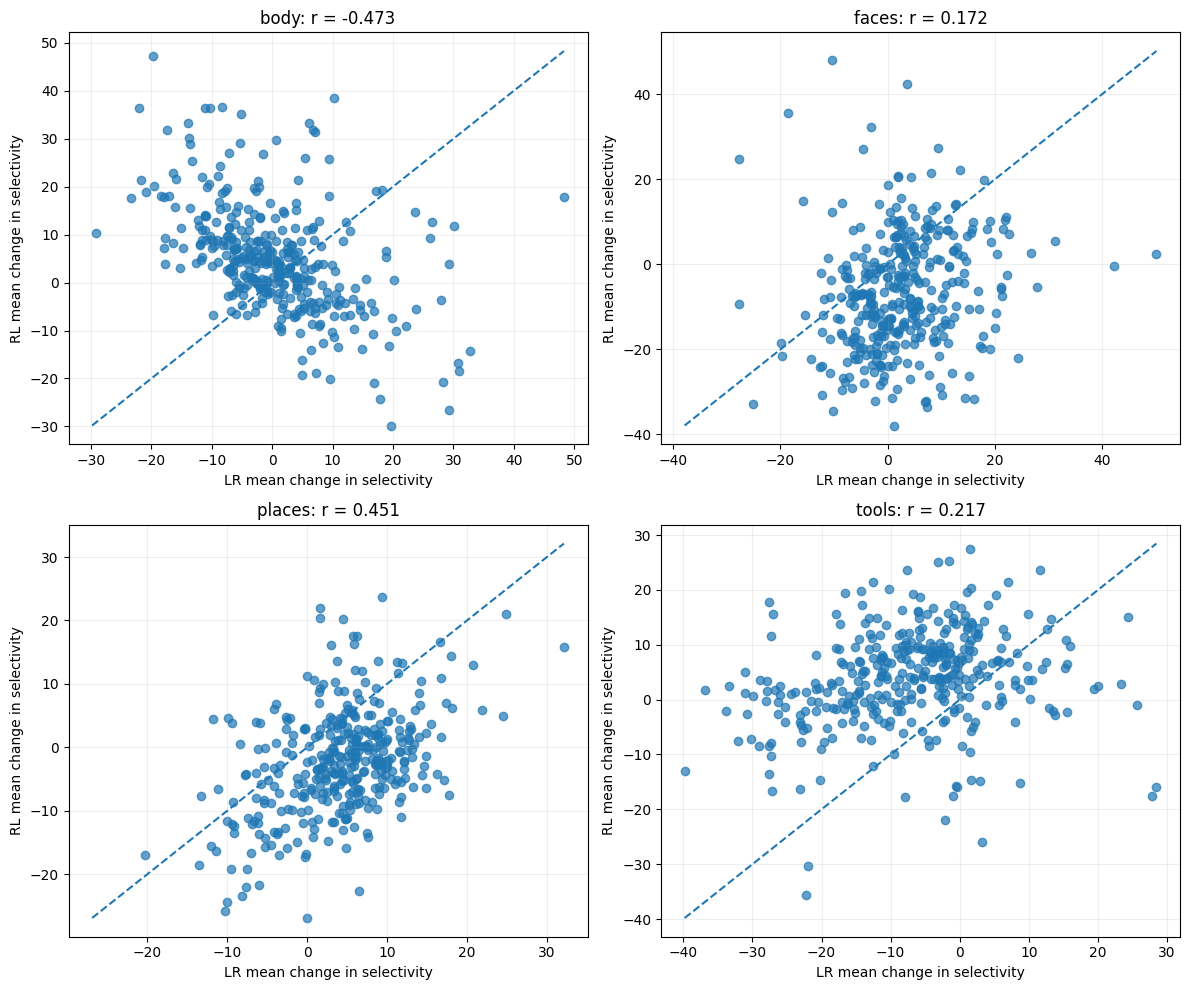

,category,pearson_r,n_parcels
0,body,-0.472924,360
1,faces,0.171651,360
2,places,0.450522,360
3,tools,0.217308,360


In [27]:
lr = run_idx["LR"]
rl = run_idx["RL"]

correlation_rows = []

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ci, category in enumerate(CATEGORIES):

    # Group-average delta-selectivity maps, one value per parcel
    x = np.nanmean(delta_sel_run[:, lr, ci, :], axis=0)
    y = np.nanmean(delta_sel_run[:, rl, ci, :], axis=0)

    valid = np.isfinite(x) & np.isfinite(y)
    r, p = pearsonr(x[valid], y[valid])

    correlation_rows.append({
        "category": category,
        "pearson_r": r,
        "n_parcels": int(valid.sum())
    })

    ax = axes[ci]
    ax.scatter(x[valid], y[valid], alpha=0.7)

    # Reference line: identical LR and RL values
    lo = min(x[valid].min(), y[valid].min())
    hi = max(x[valid].max(), y[valid].max())
    ax.plot([lo, hi], [lo, hi], linestyle="--")

    ax.set_title(f"{category}: r = {r:.3f}")
    ax.set_xlabel("LR mean change in selectivity")
    ax.set_ylabel("RL mean change in selectivity")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

correlation_results = pd.DataFrame(correlation_rows)
display(correlation_results)

In [35]:
LR = 0
target = "faces"

target_idx = [
    condition_index[f"{load}_{target}"]
    for load in LOADS
]

other_idx = [
    condition_index[f"{load}_{category}"]
    for load in LOADS
    for category in CATEGORIES
    if category != target
]

# Average target response across loads
target_values = run_betas[:, LR, target_idx, :].mean(axis=1)

# Average other-category responses across loads and categories
other_values = run_betas[:, LR, other_idx, :].mean(axis=1)

# Participant-level face selectivity
d = target_values - other_values

t_values, p_values = ttest_1samp(d, 0, axis=0)

for hemisphere in ["R_", "L_"]:
    indices = [
        i for i in np.argsort(t_values)[::-1]
        if region_names[i].startswith(hemisphere)
    ][:3]

    print(
        hemisphere,
        [
            (region_names[i], round(t_values[i], 2), p_values[i])
            for i in indices
        ]
    )

R_ [(np.str_('R_PIT'), np.float64(6.68), np.float64(1.4311436196216152e-09)), (np.str_('R_10r'), np.float64(6.52), np.float64(2.9339394618801906e-09)), (np.str_('R_FFC'), np.float64(6.4), np.float64(5.137339132894866e-09))]
L_ [(np.str_('L_10r'), np.float64(6.74), np.float64(1.0417073620828972e-09)), (np.str_('L_10v'), np.float64(6.25), np.float64(1.0311039176413285e-08)), (np.str_('L_FFC'), np.float64(5.33), np.float64(6.163812147569751e-07))]


In [36]:
from statsmodels.stats.multitest import multipletests

reject, p_fdr, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

for i in range(len(region_names)):
    if reject[i]:
        print(region_names[i], "p =", p_values[i], "FDR p =", p_fdr[i])

R_V1 p = 5.853452137723382e-20 FDR p = 1.3565277542735419e-18
R_V6 p = 9.195740899035294e-08 FDR p = 4.940995109929411e-07
R_V2 p = 2.243769628124217e-20 FDR p = 6.213515893267063e-19
R_V3 p = 7.501193837851329e-07 FDR p = 3.6005730421686376e-06
R_V4 p = 1.0355980780081738e-14 FDR p = 1.2855700278722157e-13
R_V8 p = 1.031719922679324e-15 FDR p = 1.4856766886582266e-14
R_FEF p = 0.011878811978036627 FDR p = 0.024972924581810555
R_V3A p = 3.029985460659941e-20 FDR p = 7.791391184554134e-19
R_POS2 p = 3.3913345793639855e-05 FDR p = 0.00011853208238553737
R_V7 p = 1.2710783164691195e-13 FDR p = 1.4299631060277595e-12
R_IPS1 p = 8.062406994531646e-15 FDR p = 1.0749875992708862e-13
R_FFC p = 5.137339132894866e-09 FDR p = 3.244635241828336e-08
R_V3B p = 9.091981327381739e-21 FDR p = 3.2731132778574264e-19
R_LO1 p = 3.935954802727672e-11 FDR p = 3.2952179743766554e-10
R_LO2 p = 0.00035401378473630326 FDR p = 0.0010709660714711695
R_PIT p = 1.4311436196216152e-09 FDR p = 1.0102190256152578e-08


In [37]:
mean_effect = d.mean(axis=0)
sd_effect = d.std(axis=0, ddof=1)
n = d.shape[0]
cohens_d = mean_effect / sd_effect

significant_idx = np.where(reject)[0]

results = sorted(
    [
        (
            region_names[i],
            mean_effect[i],
            t_values[i],
            p_values[i],
            p_fdr[i],
            cohens_d[i]
        )
        for i in significant_idx
    ],
    key=lambda x: x[4]
)

print("Parcel | Mean contrast | t | Raw p | FDR p | Cohen's d")
for name, effect, t, p, q, effect_size in results:
    direction = "Faces > other categories" if effect > 0 else "Other categories > faces"
    print(
        f"{name} | {effect:.4f} | {t:.2f} | "
        f"{p:.2e} | {q:.2e} | {effect_size:.3f} | {direction}"
    )

Parcel | Mean contrast | t | Raw p | FDR p | Cohen's d
R_VMV3 | -51.9332 | -17.24 | 1.44e-31 | 5.17e-29 | -1.724 | Other categories > faces
R_V3CD | -44.8204 | -16.69 | 1.54e-30 | 2.75e-28 | -1.669 | Other categories > faces
L_V3CD | -43.5544 | -16.60 | 2.30e-30 | 2.75e-28 | -1.660 | Other categories > faces
R_VMV2 | -57.0426 | -15.73 | 1.09e-28 | 9.84e-27 | -1.573 | Other categories > faces
R_PHA3 | -42.2606 | -15.25 | 9.98e-28 | 7.18e-26 | -1.525 | Other categories > faces
L_VMV3 | -60.4649 | -14.68 | 1.38e-26 | 8.30e-25 | -1.468 | Other categories > faces
L_V3B | -35.6309 | -12.63 | 2.31e-22 | 1.19e-20 | -1.263 | Other categories > faces
R_IP0 | -29.0942 | -12.46 | 5.40e-22 | 2.43e-20 | -1.246 | Other categories > faces
R_PHA2 | -37.9280 | -12.06 | 3.89e-21 | 1.55e-19 | -1.206 | Other categories > faces
R_V3B | -36.8396 | -11.88 | 9.09e-21 | 3.27e-19 | -1.188 | Other categories > faces
L_V1 | -30.0987 | -11.80 | 1.39e-20 | 4.55e-19 | -1.180 | Other categories > faces
L_IP0 | -32.868

In [38]:
# Expected:
# condition_betas: (subjects, conditions, parcels)
# condition_index: maps labels such as "0bk_faces" to condition indices
# CATEGORIES: ["body", "faces", "places", "tools"]
# LOADS: ["0bk", "2bk"]
# region_names: names of the 360 Glasser parcels

n_subjects, n_conditions, n_parcels = condition_betas.shape

# Store each participant's 2-back minus 0-back selectivity.
# Shape: (subjects, categories, parcels)
delta_selectivity = np.zeros(
    (n_subjects, len(CATEGORIES), n_parcels)
)

for c_idx, category in enumerate(CATEGORIES):

    # Calculate selectivity separately for each load
    selectivity = {}

    for load in LOADS:
        target_idx = condition_index[f"{load}_{category}"]

        other_idx = [
            condition_index[f"{load}_{other_category}"]
            for other_category in CATEGORIES
            if other_category != category
        ]

        target_beta = condition_betas[:, target_idx, :]
        other_beta = condition_betas[:, other_idx, :].mean(axis=1)

        # Each participant's category-selectivity score
        selectivity[load] = target_beta - other_beta

    # Within-participant contrast at every parcel
    delta_selectivity[:, c_idx, :] = (
        selectivity["2bk"] - selectivity["0bk"]
    )

# Group-level one-sample t-tests against zero
t_values = np.zeros((len(CATEGORIES), n_parcels))
p_values = np.zeros((len(CATEGORIES), n_parcels))
mean_delta = delta_selectivity.mean(axis=0)
cohens_d = np.zeros((len(CATEGORIES), n_parcels))

for c_idx in range(len(CATEGORIES)):
    d = delta_selectivity[:, c_idx, :]

    t_values[c_idx], p_values[c_idx] = ttest_1samp(
        d, popmean=0, axis=0
    )

    cohens_d[c_idx] = (
        d.mean(axis=0) / d.std(axis=0, ddof=1)
    )

# FDR correction across all 4 categories x 360 parcels = 1,440 tests
reject, p_fdr, _, _ = multipletests(
    p_values.ravel(),
    alpha=0.05,
    method="fdr_bh"
)

reject = reject.reshape(len(CATEGORIES), n_parcels)
p_fdr = p_fdr.reshape(len(CATEGORIES), n_parcels)

# Summarize results
for c_idx, category in enumerate(CATEGORIES):
    sig = reject[c_idx]

    print(f"\n{category.upper()}")
    print("FDR-significant parcels:", int(sig.sum()))
    print("Positive load effects:", int((sig & (mean_delta[c_idx] > 0)).sum()))
    print("Negative load effects:", int((sig & (mean_delta[c_idx] < 0)).sum()))

# Create a table of all FDR-significant results
rows = []

for c_idx, category in enumerate(CATEGORIES):
    for parcel_idx in np.where(reject[c_idx])[0]:
        rows.append({
            "category": category,
            "parcel": region_names[parcel_idx],
            "mean_delta_selectivity": mean_delta[c_idx, parcel_idx],
            "t": t_values[c_idx, parcel_idx],
            "p": p_values[c_idx, parcel_idx],
            "p_fdr": p_fdr[c_idx, parcel_idx],
            "cohens_d": cohens_d[c_idx, parcel_idx]
        })

results_df = pd.DataFrame(rows)

if not results_df.empty:
    results_df = results_df.sort_values("p_fdr")
    display(results_df)

# Save the table
results_df.to_csv(
    "within_participant_load_contrasts.csv",
    index=False
)


BODY
FDR-significant parcels: 26
Positive load effects: 26
Negative load effects: 0

FACES
FDR-significant parcels: 129
Positive load effects: 37
Negative load effects: 92

PLACES
FDR-significant parcels: 54
Positive load effects: 30
Negative load effects: 24

TOOLS
FDR-significant parcels: 69
Positive load effects: 19
Negative load effects: 50


,category,parcel,mean_delta_selectivity,t,p,p_fdr,cohens_d
17,body,L_V4,21.007567,6.471642,3.735693e-09,0.000004,0.647164
146,faces,L_VMV3,-29.045651,-6.399905,5.211239e-09,0.000004,-0.639991
98,faces,L_V2,-17.538160,-6.203733,1.285756e-08,0.000005,-0.620373
243,tools,R_p10p,-26.390041,-6.203763,1.285580e-08,0.000005,-0.620376
7,body,R_13l,33.021645,6.104846,2.018592e-08,0.000006,0.610485
...,...,...,...,...,...,...,...
30,faces,R_V3,-7.881808,-2.659063,9.139665e-03,0.048033,-0.265906
21,body,L_MI,10.206165,2.653309,9.286213e-03,0.048626,0.265331
27,faces,R_MST,8.180163,2.648758,9.403611e-03,0.048885,0.264876
171,places,R_TE1a,10.349780,2.648761,9.403533e-03,0.048885,0.264876


In [39]:
print("Condition betas:", condition_betas.shape)
print("Categories:", CATEGORIES)
print("Loads:", LOADS)
print("Subjects:", len(condition_betas))
print("Parcels:", len(region_names))
print(condition_index)

Condition betas: (100, 8, 360)
Categories: ['body', 'faces', 'places', 'tools']
Loads: ['0bk', '2bk']
Subjects: 100
Parcels: 360
{'0bk_body': 0, '0bk_faces': 1, '0bk_places': 2, '0bk_tools': 3, '2bk_body': 4, '2bk_faces': 5, '2bk_places': 6, '2bk_tools': 7}


how does place-category selectivity change with working-memory load, and which cortical parcels show those changes? (pivoted from faces due to parcel populous networks and negative  

In [40]:
places_idx = CATEGORIES.index("places")

places_results = pd.DataFrame({
    "parcel": region_names,
    "mean_delta": mean_delta[places_idx],
    "t": t_values[places_idx],
    "p_fdr": p_fdr[places_idx],
    "significant": reject[places_idx]
})

places_sig = (
    places_results[places_results["significant"]]
    .sort_values("mean_delta", ascending=False)
)

display(places_sig)

,parcel,mean_delta,t,p_fdr,significant
212,L_v23ab,23.994452,3.411308,0.009852,True
251,L_10d,22.974810,4.332514,0.000836,True
211,L_23d,16.887374,3.884954,0.003062,True
214,L_31pv,16.633430,3.597439,0.006094,True
349,L_p10p,16.516874,3.266085,0.013405,True
101,R_OP2-3,16.198886,3.895754,0.003016,True
243,L_p32,14.742883,2.814265,0.034953,True
250,L_9p,13.880705,3.352812,0.011111,True
213,L_d23ab,13.862968,2.923698,0.027685,True
281,L_OP2-3,12.401072,3.060536,0.021108,True


In [41]:
!pip -q install nibabel nilearn neuromaps

In [45]:
import os
import requests
import numpy as np

# Use the same directory as your NMA HCP dataset
HCP_DIR = "./hcp_task"
os.makedirs(HCP_DIR, exist_ok=True)

fname = os.path.join(HCP_DIR, "atlas.npz")
url = "https://osf.io/j5kuc/download"

# Download if the file is missing
if not os.path.isfile(fname):
    print("Downloading NMA atlas...")

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    # An .npz file is a ZIP archive; check before saving
    if not response.content.startswith(b"PK"):
        raise ValueError(
            "The download does not appear to be an NPZ file. "
            f"Content type: {response.headers.get('content-type')}. "
            "Check whether the OSF download succeeded."
        )

    with open(fname, "wb") as f:
        f.write(response.content)

    print("Atlas downloaded successfully.")

# Load and validate the atlas
with np.load(fname, allow_pickle=False) as dobj:
    print("Atlas keys:", dobj.files)
    atlas = {key: dobj[key] for key in dobj.files}

print("Atlas path:", os.path.abspath(fname))

for hemi in ["L", "R"]:
    key = f"labels_{hemi}"
    if key in atlas:
        print(key, "shape:", atlas[key].shape)
    else:
        print(f"WARNING: {key} is missing from the atlas.")

Atlas downloaded successfully.
Atlas keys: ['labels_R', 'labels_L', 'coords']
Atlas path: /content/hcp_task/atlas.npz
labels_L shape: (10242,)
labels_R shape: (10242,)


In [48]:
# places_effect must contain 360 values in NMA atlas order.
# Right hemisphere: parcel indices 0-179
# Left hemisphere:  parcel indices 180-359
# Label -1: unlabeled vertex

def map_effect_to_surface(hemi, parcel_effect):
    labels = np.asarray(atlas[f"labels_{hemi}"]).astype(int).ravel()

    valid = (labels >= 0) & (labels < len(parcel_effect))

    surface_map = np.zeros(labels.shape, dtype=float)
    surface_map[valid] = parcel_effect[labels[valid]]

    return surface_map

surface_left = map_effect_to_surface("L", places_effect)
surface_right = map_effect_to_surface("R", places_effect)

print("Left surface map:", surface_left.shape)
print("Right surface map:", surface_right.shape)
print("Left labeled vertices:", np.sum(atlas["labels_L"] >= 0))
print("Right labeled vertices:", np.sum(atlas["labels_R"] >= 0))

Left surface map: (10242,)
Right surface map: (10242,)
Left labeled vertices: 9374
Right labeled vertices: 9368


In [49]:
print("First 5 parcels:", region_names[:5])
print("Around parcel 180:", region_names[178:182])
print("Last 5 parcels:", region_names[-5:])

First 5 parcels: ['R_V1' 'R_MST' 'R_V6' 'R_V2' 'R_V3']
Around parcel 180: ['R_a32pr' 'R_p24' 'L_V1' 'L_MST']
Last 5 parcels: ['L_STSva' 'L_TE1m' 'L_PI' 'L_a32pr' 'L_p24']


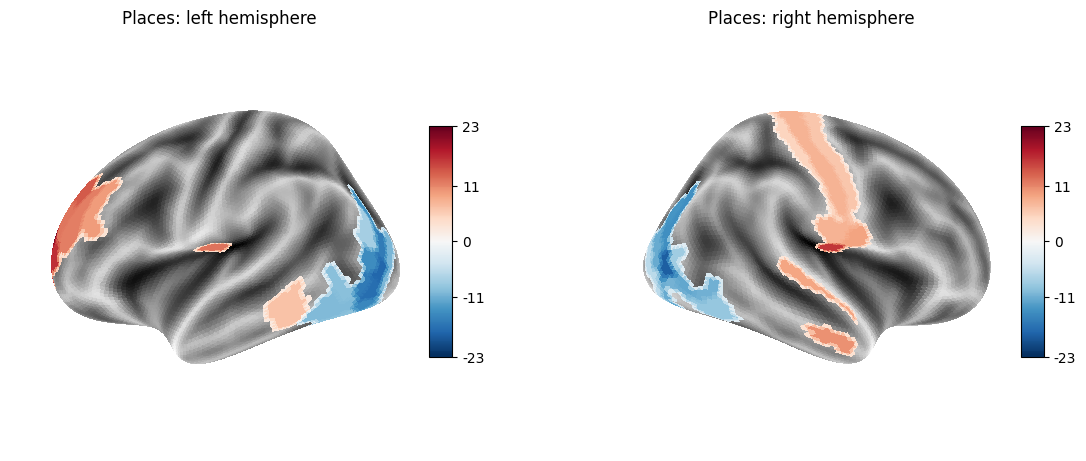

In [50]:
# Obtain the surface geometry expected by the NMA atlas
fsaverage = datasets.fetch_surf_fsaverage()

significant_effects = mean_delta[places_idx, sig]

if len(significant_effects) == 0:
    raise ValueError("No significant places parcels were found.")

limit = float(np.percentile(np.abs(significant_effects), 98))
limit = max(limit, 1e-8)

fig = plt.figure(figsize=(14, 6))

# Left hemisphere
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
plotting.plot_surf_stat_map(
    fsaverage["infl_left"],
    surface_left,
    bg_map=fsaverage["sulc_left"],
    hemi="left",
    view="lateral",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    threshold=1e-8,
    colorbar=True,
    axes=ax1,
    title="Places: left hemisphere"
)

# Right hemisphere
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
plotting.plot_surf_stat_map(
    fsaverage["infl_right"],
    surface_right,
    bg_map=fsaverage["sulc_right"],
    hemi="right",
    view="lateral",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    threshold=1e-8,
    colorbar=True,
    axes=ax2,
    title="Places: right hemisphere"
)

plt.show()

In [52]:
places_idx = CATEGORIES.index("places")

places_table = pd.DataFrame({
    "parcel": region_names,
    "mean_delta_selectivity": mean_delta[places_idx],
    "t": t_values[places_idx],
    "p_fdr": p_fdr[places_idx],
    "significant": reject[places_idx]
})

significant_places = places_table[
    places_table["significant"]
].copy()

positive_places = significant_places[
    significant_places["mean_delta_selectivity"] > 0
].sort_values("mean_delta_selectivity", ascending=False)

negative_places = significant_places[
    significant_places["mean_delta_selectivity"] < 0
].sort_values("mean_delta_selectivity")

print("INCREASED PLACES SELECTIVITY AT 2-BACK")
display(positive_places)

print("DECREASED PLACES SELECTIVITY AT 2-BACK")
display(negative_places)

INCREASED PLACES SELECTIVITY AT 2-BACK


,parcel,mean_delta_selectivity,t,p_fdr,significant
212,L_v23ab,23.994452,3.411308,0.009852,True
251,L_10d,22.974810,4.332514,0.000836,True
211,L_23d,16.887374,3.884954,0.003062,True
214,L_31pv,16.633430,3.597439,0.006094,True
349,L_p10p,16.516874,3.266085,0.013405,True
101,R_OP2-3,16.198886,3.895754,0.003016,True
243,L_p32,14.742883,2.814265,0.034953,True
250,L_9p,13.880705,3.352812,0.011111,True
213,L_d23ab,13.862968,2.923698,0.027685,True
281,L_OP2-3,12.401072,3.060536,0.021108,True


DECREASED PLACES SELECTIVITY AT 2-BACK


,parcel,mean_delta_selectivity,t,p_fdr,significant
19,R_LO1,-18.655536,-5.898246,0.000008,True
199,L_LO1,-17.993090,-4.969347,0.000140,True
200,L_LO2,-17.269927,-5.692866,0.000017,True
335,L_V4t,-16.051655,-4.742090,0.000256,True
337,L_V3CD,-15.798162,-5.059867,0.000116,True
201,L_PIT,-14.819050,-3.861987,0.003249,True
338,L_LO3,-14.325881,-5.002525,0.000134,True
157,R_V3CD,-13.898853,-4.403783,0.000659,True
145,R_IP0,-13.858526,-3.803134,0.003662,True
325,L_IP0,-13.774875,-4.705881,0.000289,True


In [53]:
# Identify 'places' index and indices of other categories
places_idx = CATEGORIES.index("places")
other_categories = [cat for cat in CATEGORIES if cat != "places"]
other_indices = [CATEGORIES.index(cat) for cat in other_categories]

# Get indices of the FDR-significant places parcels
sig_places_indices = np.where(reject[places_idx])[0]
sig_places_names = region_names[sig_places_indices]

print(f"Found {len(sig_places_indices)} significant parcels for places.")

# Extract condition betas for 0bk and 2bk
# condition_betas shape: (subjects, conditions, parcels)

# 0bk and 2bk indices for places
places_0bk_cond_idx = condition_index["0bk_places"]
places_2bk_cond_idx = condition_index["2bk_places"]

# 0bk and 2bk indices for other categories
others_0bk_cond_indices = [condition_index[f"0bk_{cat}"] for cat in other_categories]
others_2bk_cond_indices = [condition_index[f"2bk_{cat}"] for cat in other_categories]

# Calculate Delta Beta Places: 2bk_places - 0bk_places (subjects x parcels)
delta_beta_places = (
    condition_betas[:, places_2bk_cond_idx, :]
    - condition_betas[:, places_0bk_cond_idx, :]
)

# Calculate Delta Beta Other:
# mean across other categories of (2bk_other - 0bk_other)
beta_other_2bk = condition_betas[:, others_2bk_cond_indices, :].mean(axis=1)
beta_other_0bk = condition_betas[:, others_0bk_cond_indices, :].mean(axis=1)
delta_beta_other = beta_other_2bk - beta_other_0bk

# Verify that Delta S_places = Delta Beta Places - Delta Beta Other
# delta_selectivity shape: (subjects, categories, parcels)
delta_selectivity_places = delta_selectivity[:, places_idx, :]

calculated_delta_selectivity = delta_beta_places - delta_beta_other

# Check if they are numerically identical
is_verified = np.allclose(delta_selectivity_places, calculated_delta_selectivity)
max_absolute_difference = np.max(np.abs(delta_selectivity_places - calculated_delta_selectivity))

print(f"Verification Status: {'SUCCESS' if is_verified else 'FAILED'}")
print(f"Maximum Absolute Numerical Difference: {max_absolute_difference:.2e}")

# Build a summary dataframe for the significant parcels
verification_rows = []
for i, parcel_idx in enumerate(sig_places_indices):
    verification_rows.append({
        "parcel_index": parcel_idx,
        "parcel_name": region_names[parcel_idx],
        "mean_delta_beta_places": delta_beta_places[:, parcel_idx].mean(),
        "mean_delta_beta_other": delta_beta_other[:, parcel_idx].mean(),
        "mean_delta_selectivity_direct": delta_selectivity_places[:, parcel_idx].mean(),
        "mean_delta_selectivity_calculated": calculated_delta_selectivity[:, parcel_idx].mean()
    })

verification_df = pd.DataFrame(verification_rows)
display(verification_df.head(10))

Found 54 significant parcels for places.
Verification Status: SUCCESS
Maximum Absolute Numerical Difference: 1.14e-13


,parcel_index,parcel_name,mean_delta_beta_places,mean_delta_beta_other,mean_delta_selectivity_direct,mean_delta_selectivity_calculated
0,4,R_V3,-6.159844,-0.060298,-6.099546,-6.099546
1,5,R_V4,-11.302012,0.065090,-11.367102,-11.367102
2,7,R_4,-1.298857,-7.665250,6.366393,6.366393
3,8,R_3b,-0.877365,-8.715640,7.838275,7.838275
4,18,R_V3B,-12.756568,0.648640,-13.405208,-13.405208
5,19,R_LO1,-21.746700,-3.091164,-18.655536,-18.655536
6,20,R_LO2,-16.744163,-5.997770,-10.746392,-10.746392
7,31,R_23d,9.121553,-2.197146,11.318699,11.318699
8,35,R_5m,0.911886,-7.841176,8.753062,8.753062
9,39,R_24dd,-0.435921,-8.408110,7.972188,7.972188


In [56]:
from statsmodels.stats.multitest import multipletests
from scipy.stats import t as t_dist
rows = []

for parcel_idx in sig_places_indices:

    for component_name, values in [
        ("places_response", delta_beta_places[:, parcel_idx]),
        ("other_categories_mean", delta_beta_other[:, parcel_idx])
    ]:
        n = np.sum(np.isfinite(values))
        x = values[np.isfinite(values)]

        mean_change = x.mean()
        sd = x.std(ddof=1)
        se = sd / np.sqrt(n)

        t_value, p_value = ttest_1samp(x, 0)

        ci_low = mean_change - t_dist.ppf(0.975, n - 1) * se
        ci_high = mean_change + t_dist.ppf(0.975, n - 1) * se

        rows.append({
            "parcel": region_names[parcel_idx],
            "component": component_name,
            "mean_change": mean_change,
            "ci95_low": ci_low,
            "ci95_high": ci_high,
            "t": t_value,
            "p": p_value
        })

component_df = pd.DataFrame(rows)

# Exploratory correction across the 54 parcels x 2 components
component_df["p_fdr"] = multipletests(
    component_df["p"],
    method="fdr_bh"
)[1]

display(
    component_df.sort_values(
        ["component", "p_fdr"]
    ).reset_index(drop=True)
)

,parcel,component,mean_change,ci95_low,ci95_high,t,p,p_fdr
0,L_v23ab,other_categories_mean,-24.311261,-28.594658,-20.027865,-11.261814,1.981112e-19,2.139601e-17
1,R_OP4,other_categories_mean,-12.296667,-14.525873,-10.067462,-10.945271,9.594868e-19,5.181229e-17
2,L_OP2-3,other_categories_mean,-18.650792,-22.254047,-15.047537,-10.270497,2.813291e-17,1.012785e-15
3,R_3b,other_categories_mean,-8.715640,-10.610140,-6.821140,-9.128382,8.706933e-15,2.350872e-13
4,L_31pv,other_categories_mean,-18.020584,-22.099511,-13.941656,-8.766213,5.336154e-14,8.232923e-13
...,...,...,...,...,...,...,...,...
103,R_24dd,places_response,-0.435921,-5.840213,4.968371,-0.160051,8.731670e-01,9.336835e-01
104,L_d23ab,places_response,0.495752,-8.684353,9.675858,0.107153,9.148841e-01,9.592959e-01
105,L_24dd,places_response,0.291195,-4.712097,5.294486,0.115483,9.082965e-01,9.592959e-01
106,R_OP2-3,places_response,0.210470,-9.617366,10.038306,0.042493,9.661909e-01,9.752207e-01


In [57]:
# Target parcels requested
key_decreases = ['R_LO1', 'L_LO2', 'L_V3CD', 'L_PIT']
key_increases = ['L_v23ab', 'L_10d', 'R_23d']
target_parcels = key_decreases + key_increases

# Build a clean dataframe of raw beta changes for these specific parcels
b_rows = []
for p_name in target_parcels:
    if p_name not in region_names:
        continue
    p_idx = list(region_names).index(p_name)

    # For each subject, extract relevant condition betas
    # Places responses
    p_0bk = condition_betas[:, condition_index['0bk_places'], p_idx]
    p_2bk = condition_betas[:, condition_index['2bk_places'], p_idx]

    # Other category average responses
    other_cats = [c for c in CATEGORIES if c != 'places']
    other_0bk_idx = [condition_index[f'0bk_{c}'] for c in other_cats]
    other_2bk_idx = [condition_index[f'2bk_{c}'] for c in other_cats]

    oth_0bk = condition_betas[:, other_0bk_idx, p_idx].mean(axis=1)
    oth_2bk = condition_betas[:, other_2bk_idx, p_idx].mean(axis=1)

    # Compute mean changes and standard errors across subjects
    b_rows.append({
        "parcel": p_name,
        "class": "Decrease ROI" if p_name in key_decreases else "Increase ROI",
        "Places_0bk": p_0bk.mean(),
        "Places_2bk": p_2bk.mean(),
        "Places_Change": (p_2bk - p_0bk).mean(),
        "Competitors_0bk": oth_0bk.mean(),
        "Competitors_2bk": oth_2bk.mean(),
        "Competitors_Change": (oth_2bk - oth_0bk).mean(),
        "Net_Selectivity_Change": ((p_2bk - oth_2bk) - (p_0bk - oth_0bk)).mean()
    })

beta_comparison_df = pd.DataFrame(b_rows)
display(beta_comparison_df.round(3))

,parcel,class,Places_0bk,Places_2bk,Places_Change,Competitors_0bk,Competitors_2bk,Competitors_Change,Net_Selectivity_Change
0,R_LO1,Decrease ROI,53.410,31.663,-21.747,31.283,28.192,-3.091,-18.656
1,L_LO2,Decrease ROI,36.423,19.115,-17.307,42.326,42.289,-0.037,-17.270
2,L_V3CD,Decrease ROI,78.837,63.688,-15.149,27.971,28.621,0.649,-15.798
3,L_PIT,Decrease ROI,54.146,42.892,-11.254,56.344,59.909,3.565,-14.819
4,L_v23ab,Increase ROI,10.893,10.576,-0.317,24.847,0.536,-24.311,23.994
5,L_10d,Increase ROI,5.778,12.001,6.223,20.497,3.746,-16.751,22.975
6,R_23d,Increase ROI,17.927,27.049,9.122,27.330,25.133,-2.197,11.319


In [58]:
parcels_to_check = [
    "L_v23ab", "L_10d", "R_23d",
    "R_LO1", "L_LO2", "L_V3CD", "L_PIT"
]

rows = []

for parcel in parcels_to_check:
    p_idx = list(region_names).index(parcel)

    for category in CATEGORIES:
        idx_0 = condition_index[f"0bk_{category}"]
        idx_2 = condition_index[f"2bk_{category}"]

        beta_0 = condition_betas[:, idx_0, p_idx]
        beta_2 = condition_betas[:, idx_2, p_idx]
        change = beta_2 - beta_0

        rows.append({
            "parcel": parcel,
            "category": category,
            "mean_0bk": np.nanmean(beta_0),
            "mean_2bk": np.nanmean(beta_2),
            "mean_change": np.nanmean(change),
            "median_change": np.nanmedian(change),
            "SD_change": np.nanstd(change, ddof=1),
            "n": np.sum(np.isfinite(change))
        })

condition_detail_df = pd.DataFrame(rows)

display(
    condition_detail_df.round(3)
    .sort_values(["parcel", "category"])
    .reset_index(drop=True)
)

,parcel,category,mean_0bk,mean_2bk,mean_change,median_change,SD_change,n
0,L_10d,body,17.449,12.179,-5.270,-9.092,44.787,100
1,L_10d,faces,27.412,2.646,-24.766,-22.055,42.611,100
2,L_10d,places,5.778,12.001,6.223,2.312,44.220,100
3,L_10d,tools,16.630,-3.588,-20.218,-19.309,42.231,100
4,L_LO2,body,48.585,47.114,-1.471,0.334,43.604,100
5,L_LO2,faces,33.918,43.328,9.410,6.995,32.522,100
6,L_LO2,places,36.423,19.115,-17.307,-14.538,28.814,100
7,L_LO2,tools,44.476,36.425,-8.051,-5.055,29.784,100
8,L_PIT,body,54.800,61.560,6.761,12.077,51.922,100
9,L_PIT,faces,56.709,65.051,8.342,8.995,33.861,100


In [59]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

parcels_to_check = [
    "R_LO1", "L_LO2", "L_V3CD", "L_PIT",
    "L_v23ab", "L_10d", "R_23d"
]

rows = []

for parcel in parcels_to_check:
    p_idx = list(region_names).index(parcel)

    for category in CATEGORIES:
        idx0 = condition_index[f"0bk_{category}"]
        idx2 = condition_index[f"2bk_{category}"]

        change = (
            condition_betas[:, idx2, p_idx]
            - condition_betas[:, idx0, p_idx]
        )
        change = change[np.isfinite(change)]

        t_stat, p_t = ttest_1samp(change, 0)

        # Robust complementary test of the paired changes
        try:
            p_w = (
                wilcoxon(change).pvalue
                if np.any(change != 0)
                else 1.0
            )
        except ValueError:
            p_w = np.nan

        n = len(change)
        se = change.std(ddof=1) / np.sqrt(n)

        rows.append({
            "parcel": parcel,
            "category": category,
            "mean_change": change.mean(),
            "median_change": np.median(change),
            "SD_change": change.std(ddof=1),
            "CI95_low": change.mean() - 1.984 * se,
            "CI95_high": change.mean() + 1.984 * se,
            "t": t_stat,
            "p_t": p_t,
            "p_wilcoxon": p_w,
            "n": n
        })

component_tests = pd.DataFrame(rows)

# Correct the 28 t-tests (7 parcels x 4 categories)
component_tests["p_t_FDR"] = multipletests(
    component_tests["p_t"],
    method="fdr_bh"
)[1]

display(
    component_tests.sort_values(
        ["parcel", "category"]
    ).round(4)
)

,parcel,category,mean_change,median_change,SD_change,CI95_low,CI95_high,t,p_t,p_wilcoxon,n,p_t_FDR
20,L_10d,body,-5.2701,-9.0918,44.7875,-14.1559,3.6158,-1.1767,0.2421,0.0783,100,0.3229
21,L_10d,faces,-24.7662,-22.0551,42.6113,-33.2203,-16.3121,-5.8121,0.0000,0.0000,100,0.0000
22,L_10d,places,6.2234,2.3121,44.2199,-2.5498,14.9967,1.4074,0.1624,0.4724,100,0.2527
23,L_10d,tools,-20.2178,-19.3094,42.2309,-28.5964,-11.8392,-4.7874,0.0000,0.0000,100,0.0000
4,L_LO2,body,-1.4707,0.3338,43.6045,-10.1218,7.1805,-0.3373,0.7366,0.8018,100,0.8250
5,L_LO2,faces,9.4100,6.9952,32.5219,2.9576,15.8623,2.8934,0.0047,0.0008,100,0.0109
6,L_LO2,places,-17.3072,-14.5379,28.8136,-23.0238,-11.5906,-6.0066,0.0000,0.0000,100,0.0000
7,L_LO2,tools,-8.0511,-5.0547,29.7837,-13.9602,-2.1420,-2.7032,0.0081,0.0134,100,0.0174
12,L_PIT,body,6.7605,12.0773,51.9215,-3.5407,17.0618,1.3021,0.1959,0.0035,100,0.2887
13,L_PIT,faces,8.3416,8.9950,33.8612,1.6235,15.0596,2.4635,0.0155,0.0064,100,0.0289


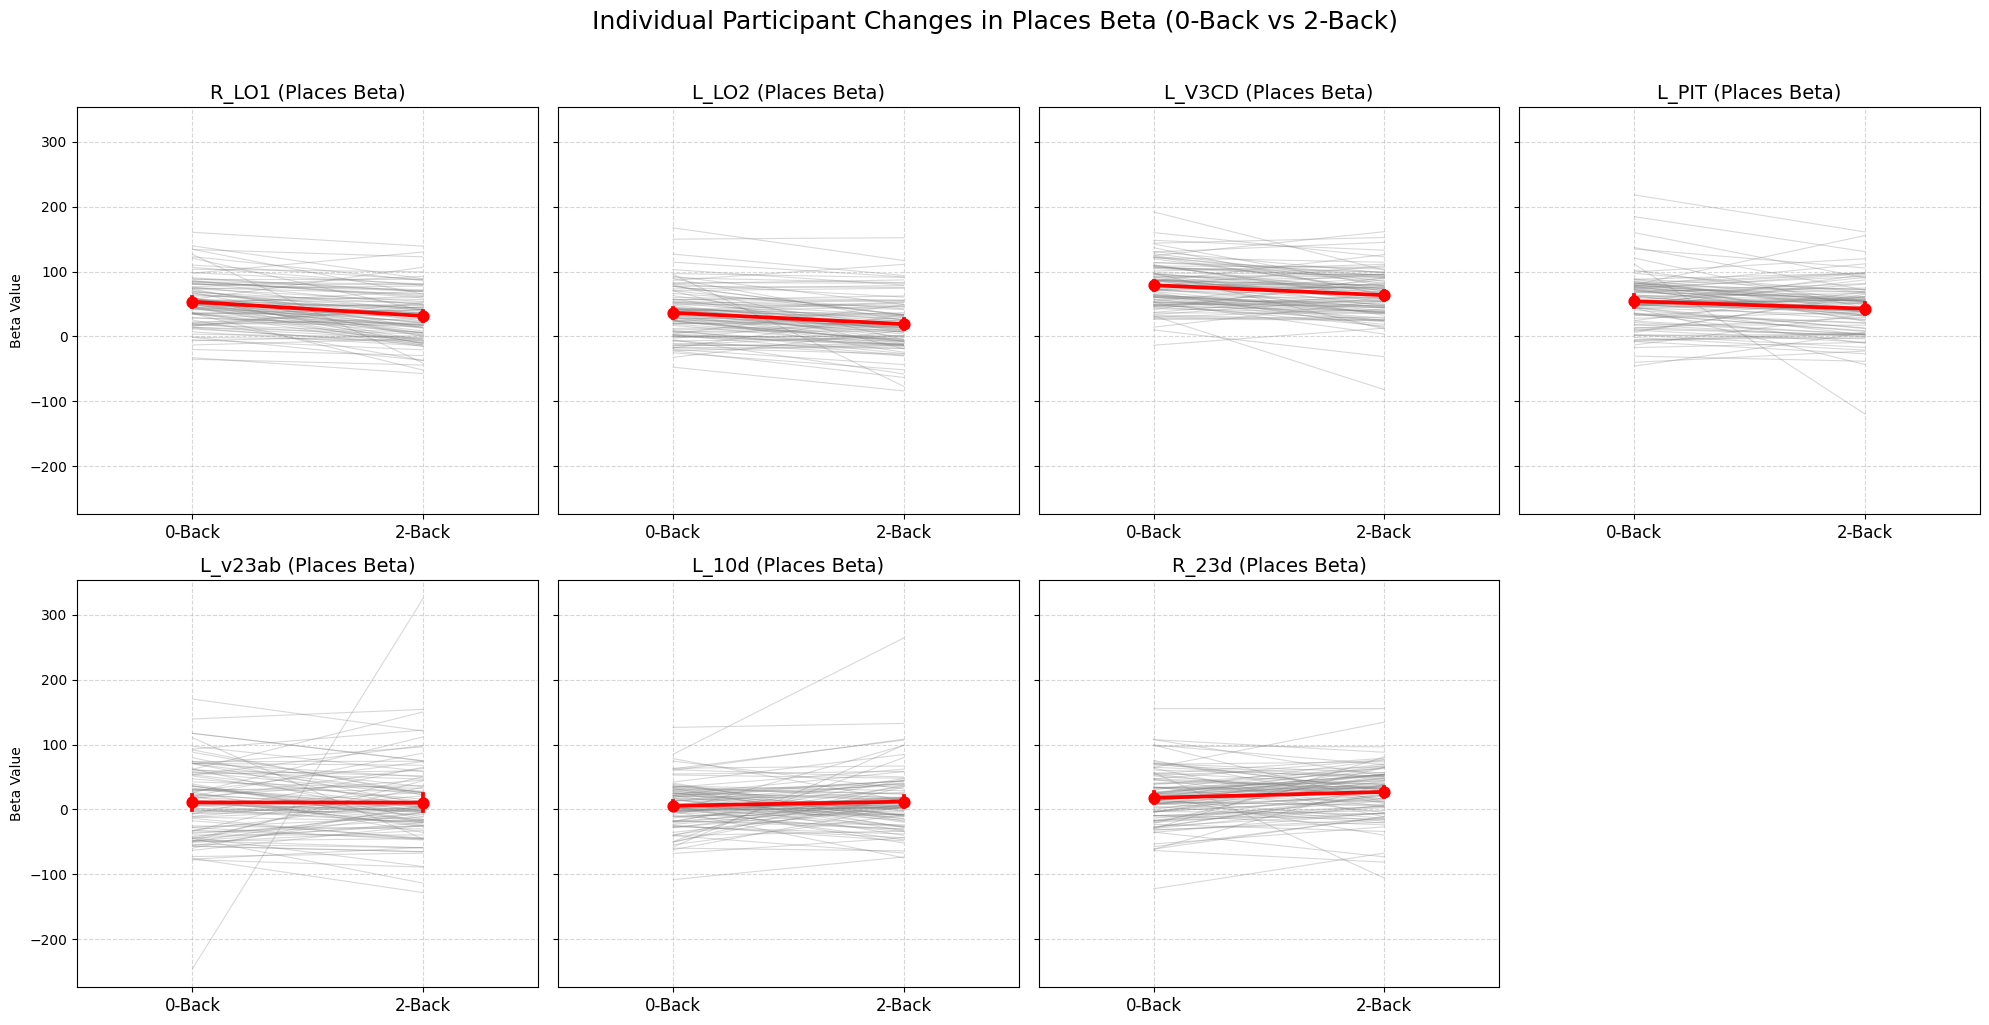

In [61]:
# Define the target parcels
key_decreases = ['R_LO1', 'L_LO2', 'L_V3CD', 'L_PIT']
key_increases = ['L_v23ab', 'L_10d', 'R_23d']
target_parcels = key_decreases + key_increases

# Prepare data for plotting
plot_data = []

for parcel in target_parcels:
    if parcel not in region_names:
        continue
    p_idx = list(region_names).index(parcel)

    p_0bk_idx = condition_index['0bk_places']
    p_2bk_idx = condition_index['2bk_places']

    p_0bk = condition_betas[:, p_0bk_idx, p_idx]
    p_2bk = condition_betas[:, p_2bk_idx, p_idx]

    for subj_idx in range(len(subjects)):
        plot_data.append({
            "Subject": subj_idx,
            "Parcel": parcel,
            "ROI_Type": "Selectivity Decrease" if parcel in key_decreases else "Selectivity Increase",
            "Load": "0-Back",
            "Beta": p_0bk[subj_idx]
        })
        plot_data.append({
            "Subject": subj_idx,
            "Parcel": parcel,
            "ROI_Type": "Selectivity Decrease" if parcel in key_decreases else "Selectivity Increase",
            "Load": "2-Back",
            "Beta": p_2bk[subj_idx]
        })

pair_df = pd.DataFrame(plot_data)

# Plotting
fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharey=True)
axes = axes.ravel()

for i, parcel in enumerate(target_parcels):
    ax = axes[i]
    parcel_df = pair_df[pair_df["Parcel"] == parcel]

    # Plot individual subject lines
    for subj in range(len(subjects)):
        subj_data = parcel_df[parcel_df["Subject"] == subj]
        ax.plot([0, 1], [subj_data[subj_data["Load"] == "0-Back"]["Beta"].values[0],
                        subj_data[subj_data["Load"] == "2-Back"]["Beta"].values[0]],
                color='gray', alpha=0.3, linewidth=0.8)

    # Plot group level mean with error bars
    sns.pointplot(data=parcel_df, x="Load", y="Beta", ax=ax, color='red', errorbar='ci')

    ax.set_title(f"{parcel} (Places Beta)", fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("Beta Value" if i % 4 == 0 else "")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["0-Back", "2-Back"], fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)

# Hide any unused axes
for j in range(len(target_parcels), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Individual Participant Changes in Places Beta (0-Back vs 2-Back)", fontsize=18, y=1.02)
plt.tight_layout()
plt.show()